# Segunda entrega — Datos, modelamiento y validación
### Proyecto Integrador · Machine Learning I · Universidad Externado de Colombia
**Localización interior mediante RSSI WiFi y kNN — reconstrucción del artículo QA-kNN (Ferreira et al., 2020)**
**Sebastián Ramos · Daniel Cipagauta**

Este notebook es el anexo de código del informe de la Segunda entrega. Corre de principio a fin con una semilla fija (`SEED = 42`) y genera todas las figuras (`figuras/`) y cifras (`resultados.json`) citadas en el informe.

| Sección | Contenido | Sección del informe |
|---|---|---|
| 1 | Simulación fundamentada (modelo generador) | 2.1 |
| 2 | Anclaje con datos reales: mediciones del artículo y piloto propio | 2.1 / correcciones |
| 3 | Consolidación del dataset y calidad | 2.1 |
| 4 | Partición por días y verificación empírica de supuestos | 2.1 / 2.4 |
| 5 | Flujo sin fuga (Pipeline) | 2.2 |
| 6 | Ajuste de hiperparámetros y comparación de modelos | 2.3 |
| 7 | Evaluación final en prueba, con variabilidad | 2.4 |
| 8 | Reproducción de los objetivos del artículo (barrido n×k, cuartiles vs. media, datos reales) | 2.3 / 2.4 |
| 9 | Interpretación preliminar del mejor modelo | 2.4 |

**Requisitos:** Python ≥ 3.10, numpy, pandas, scipy, scikit-learn, matplotlib. Los datos reales del artículo se descargan automáticamente del repositorio público de los autores si no están en `datos_reales_articulo/`. El piloto propio se lee de `datos_piloto/*.csv` (generado con `piloto_rssi_windows.py`).

**Declaración de uso de IA:** usamos un asistente de IA generativa (Claude, de Anthropic) como apoyo para estructurar el código, revisar la redacción y proponer verificaciones. Todas las decisiones de modelamiento fueron revisadas por el equipo, que puede sustentarlas.

In [1]:
import os, json, glob, time, warnings, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from scipy import stats

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.model_selection import GroupKFold, StratifiedKFold, GridSearchCV, cross_validate, cross_val_score
from sklearn.metrics import accuracy_score, f1_score, make_scorer, confusion_matrix, silhouette_score
from sklearn.feature_selection import f_classif

SEED = 42
np.random.seed(SEED)
warnings.filterwarnings("ignore")
os.makedirs("figuras", exist_ok=True)
os.makedirs("datos", exist_ok=True)
RES = {}

# Paleta categórica validada (orden fijo, nunca cíclico) y tintas neutras
GRIS, TINTA, TINTA2 = "#898781", "#0b0b0b", "#52514e"
COL = {"Línea base": GRIS, "kNN": "#2a78d6", "Naive Bayes": "#eb6834",
       "Regresión logística": "#1baf7a", "LDA": "#eda100", "QDA": "#e87ba4"}
FUENTE = {"Real (artículo)": "#2a78d6", "Piloto propio": "#eb6834", "Simulación": "#1baf7a"}
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 8.5,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#c3c2b7", "axes.labelcolor": TINTA2,
                     "xtick.color": TINTA2, "ytick.color": TINTA2,
                     "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
                     "legend.frameon": False})
def guardar(fig, nombre):
    fig.savefig(f"figuras/{nombre}.png", bbox_inches="tight", facecolor="white")

## 1. Simulación fundamentada: el modelo generador

Cambios frente a la Primera entrega (motivados por la retroalimentación y por los datos reales de la Sección 2):

* **Separamos dos fuentes de variación que antes estaban mezcladas.** En la Fase 1 usábamos σ = 6 dB como ruido *en cada lectura*. Las mediciones reales del artículo muestran que la sombra de ~5–6 dB es **espacial** (fija en cada sitio), mientras que la fluctuación entre lecturas repetidas en el mismo punto es de solo ~1–2 dB. Ahora la sombra es un campo aleatorio espacialmente correlacionado y la fluctuación temporal es pequeña.
* **Paredes explícitas (modelo multipared COST 231)** en lugar de cambiar el exponente por zona: la señal pierde 6 dB por muro de corredor y 4 dB por tabique atravesado.
* **Asimetría por obstáculos:** cuando no hay línea de vista, la fluctuación crece y aparecen caídas profundas ocasionales (personas, multitrayecto). Este es el mecanismo que el artículo usa para justificar Q1 y Q3 (Tabla 2 del artículo).
* **Realismo operativo:** posición aleatoria dentro de la zona en cada visita, deriva diaria por AP, cuantización a dBm enteros, detección intermitente de APs débiles (curva calibrada con nuestro piloto), sensibilidad de −95 dBm y fallas de AP (3 %). Todo esto produce **datos faltantes** realistas.

In [2]:
"""
Simulación fundamentada de RSSI WiFi para un piso de edificio universitario colombiano.
Proyecto Integrador ML1 — Segunda entrega (Sebastián Ramos · Daniel Cipagauta).

Modelo generador (una lectura del AP a en la posición p, día t, instante j):

    RSSI = P0_a − 10·n·log10(d/d0) − Σ_paredes L_w  +  S_a(p)  +  D_{t,a}  +  e_j  −  F_j

    P0_a      potencia a 1 m de cada AP (hardware distinto)          ~ N(−41, 2²) dBm
    n         exponente de pérdida de trayecto (con paredes explícitas) = 2.2
    L_w       atenuación por pared atravesada (COST 231 multipared): 6 dB muro de corredor, 4 dB tabique
    S_a(p)    sombra espacial: campo gaussiano con correlación exponencial (σ = 5 dB, 3 m) — fijo en el sitio
    D_{t,a}   deriva diaria por AP (ocupación, puertas, humedad)       ~ N(0, 1²) dB
    e_j       fluctuación temporal AR(1) (φ = 0.3), σ_t = 0.8 + 0.35·paredes dB
    F_j       desvanecimiento profundo ocasional (personas, multitrayecto): prob. 0.02 + 0.03·paredes,
              magnitud ~ Exp(media 4 dB) → cola izquierda (asimetría negativa)

Las lecturas se redondean a dBm enteros. Cada lectura se detecta con probabilidad logística
p = 1 / (1 + exp(−(RSSI + 91) / 2)) (escaneos que no captan el beacon de APs débiles) y nunca por
debajo de la sensibilidad (−95 dBm). σ_S, σ_t en línea de vista, φ y la deriva están calibrados con las
mediciones reales publicadas por los autores del artículo (Wi-FiPowerInOfficeDataset, Manaus, Brasil);
la curva de detección, con el piloto propio.
"""
import numpy as np
import pandas as pd

# --- Geometría del piso (30 m × 20 m): aulas abajo, corredor central, aulas/oficinas arriba ---
ANCHO, FONDO = 30.0, 20.0
COLS = 6
Y_CORREDOR = (8.0, 12.0)
FILAS = [(0.0, 8.0, "Aula"), (8.0, 12.0, "Corredor"), (12.0, 20.0, "Oficina")]

ZONAS = []  # (id, x0, x1, y0, y1, tipo)
for fila, (y0, y1, tipo) in enumerate(FILAS):
    for c in range(COLS):
        zid = fila * COLS + c + 1
        ZONAS.append((f"Z{zid:02d}", c * 5.0, (c + 1) * 5.0, y0, y1, tipo))
ZONA_IDX = {z[0]: i for i, z in enumerate(ZONAS)}
CENTROS = np.array([[(z[1] + z[2]) / 2, (z[3] + z[4]) / 2] for z in ZONAS])

# 8 APs: 4 en el corredor (instalación típica de red universitaria) y 4 dentro de aulas/oficinas,
# en posiciones no simétricas para que el piso no tenga zonas "espejo".
APS = np.array([
    [3.0, 10.0], [12.5, 10.0], [19.0, 10.0], [27.5, 10.0],   # corredor
    [7.5, 3.0], [23.0, 5.5],                                 # aulas
    [2.5, 16.5], [16.5, 17.5],                               # oficinas
])
N_APS = len(APS)

P0_MEDIA, P0_SD = -41.0, 2.0
N_PL = 2.2
L_CORREDOR, L_TABIQUE = 6.0, 4.0
SIGMA_SOMBRA, DIST_CORR = 5.0, 3.0
SIGMA_DIA = 1.0
PHI_AR = 0.3
SENSIBILIDAD = -95.0
DET_CENTRO, DET_ESCALA = -91.0, 2.0
P_FALLA_AP = 0.03


def paredes_atravesadas(p, ap):
    """Cuenta muros de corredor (y=8, y=12) y tabiques (x=5,10,...,25 fuera del corredor)
    que cruza el segmento p→ap. Devuelve (n_muros, n_tabiques)."""
    (x1, y1), (x2, y2) = p, ap
    muros = sum(1 for yw in Y_CORREDOR if (y1 - yw) * (y2 - yw) < 0)
    tabiques = 0
    for xw in np.arange(5.0, ANCHO, 5.0):
        if (x1 - xw) * (x2 - xw) < 0:
            t = (xw - x1) / (x2 - x1)
            yc = y1 + t * (y2 - y1)
            if not (Y_CORREDOR[0] < yc < Y_CORREDOR[1]):
                tabiques += 1
    return muros, tabiques


def campo_sombra(rng, res=0.5):
    """Campo gaussiano 2D con covarianza exponencial (Gudmundson) para cada AP."""
    xs = np.arange(0, ANCHO + res / 2, res)
    ys = np.arange(0, FONDO + res / 2, res)
    gx, gy = np.meshgrid(xs, ys)
    pts = np.column_stack([gx.ravel(), gy.ravel()])
    d = np.sqrt(((pts[:, None, :] - pts[None, :, :]) ** 2).sum(-1))
    L = np.linalg.cholesky(SIGMA_SOMBRA ** 2 * np.exp(-d / DIST_CORR) + 1e-6 * np.eye(len(pts)))
    campos = np.stack([(L @ rng.standard_normal(len(pts))).reshape(gy.shape) for _ in range(N_APS)])
    return xs, ys, campos


def construir_edificio(seed=42):
    """Parámetros fijos del 'edificio': potencia de cada AP y mapa de sombra espacial."""
    rng = np.random.default_rng(seed)
    p0 = rng.normal(P0_MEDIA, P0_SD, N_APS)
    xs, ys, campos = campo_sombra(rng)
    return dict(p0=p0, xs=xs, ys=ys, campos=campos)


def nivel_medio(edif, p, a):
    """Nivel determinístico + sombra espacial (sin ruido temporal) del AP a en la posición p."""
    d = max(np.hypot(*(p - APS[a])), 1.0)
    muros, tabiques = paredes_atravesadas(p, APS[a])
    ix = int(round(p[0] / 0.5)); iy = int(round(p[1] / 0.5))
    sombra = edif["campos"][a, iy, ix]
    nivel = edif["p0"][a] - 10 * N_PL * np.log10(d) - muros * L_CORREDOR - tabiques * L_TABIQUE + sombra
    return nivel, muros + tabiques


def lecturas_visita(edif, p, deriva_dia, rng, m=40):
    """Matriz m × N_APS de lecturas RSSI (dBm enteros, NaN si no se detecta) en una visita."""
    A = np.full((m, N_APS), np.nan)
    for a in range(N_APS):
        nivel, paredes = nivel_medio(edif, p, a)
        sigma_t = 0.8 + 0.35 * paredes
        e = np.empty(m)
        e[0] = rng.normal(0, sigma_t)
        innov = rng.normal(0, sigma_t * np.sqrt(1 - PHI_AR ** 2), m)
        for j in range(1, m):
            e[j] = PHI_AR * e[j - 1] + innov[j]
        p_fade = min(0.02 + 0.03 * paredes, 0.2)
        fades = (rng.random(m) < p_fade) * rng.exponential(4.0, m)
        r = np.round(nivel + deriva_dia[a] + e - fades)
        detectada = rng.random(m) < 1 / (1 + np.exp(-(r - DET_CENTRO) / DET_ESCALA))
        r[(r < SENSIBILIDAD) | ~detectada] = np.nan
        A[:, a] = r
    return A


def generar_dataset(n_dias=14, visitas_por_dia=20, m=40, seed=42, min_detecciones=10):
    """Genera el dataset de instancias (una visita = una fila) con:
    - 24 predictores Q1, Q2, Q3 por AP (representación del artículo),
    - columnas auxiliares para comparar representaciones (media y lectura cruda única),
    - metadatos: zona (objetivo), día (grupo), posición real x, y (NO son predictores)."""
    edif = construir_edificio(seed)
    rng = np.random.default_rng(seed + 1)
    filas = []
    for dia in range(1, n_dias + 1):
        deriva = rng.normal(0, SIGMA_DIA, N_APS)
        for zid, x0, x1, y0, y1, tipo in ZONAS:
            for _ in range(visitas_por_dia):
                p = np.array([rng.uniform(x0 + 0.3, x1 - 0.3), rng.uniform(y0 + 0.3, y1 - 0.3)])
                A = lecturas_visita(edif, p, deriva, rng, m)
                caidos = rng.random(N_APS) < P_FALLA_AP          # AP apagado/reiniciándose
                A[:, caidos] = np.nan
                fila = {}
                for a in range(N_APS):
                    v = A[:, a][~np.isnan(A[:, a])]
                    ok = len(v) >= min_detecciones
                    q = np.percentile(v, [25, 50, 75]) if ok else [np.nan] * 3
                    fila[f"AP{a+1}_Q1"], fila[f"AP{a+1}_Q2"], fila[f"AP{a+1}_Q3"] = q
                    fila[f"AP{a+1}_media"] = v.mean() if ok else np.nan
                    fila[f"AP{a+1}_cruda"] = A[0, a]
                fila.update(zona=zid, tipo=tipo, dia=dia, x=p[0], y=p[1])
                filas.append(fila)
    return pd.DataFrame(filas), edif


def columnas(representacion="cuartiles", aps=None):
    aps = range(1, N_APS + 1) if aps is None else aps
    if representacion == "cuartiles":
        return [f"AP{a}_{q}" for a in aps for q in ("Q1", "Q2", "Q3")]
    if representacion == "mediana":
        return [f"AP{a}_Q2" for a in aps]
    if representacion == "media":
        return [f"AP{a}_media" for a in aps]
    if representacion == "cruda":
        return [f"AP{a}_cruda" for a in aps]
    raise ValueError(representacion)

## 2. Anclaje con datos reales

Dos fuentes reales:
1. **Mediciones publicadas por los autores del artículo** (*Wi-FiPowerInOfficeDataset*, Manaus, Brasil — datos latinoamericanos): 3 520 lecturas crudas, 16 RPs × 220 lecturas, 8 APs.
2. **Piloto propio** con `piloto_rssi_windows.py` (API nativa de WiFi de Windows, BSSID anonimizados).

Con ellas estimamos o contrastamos los parámetros de la simulación.

In [3]:
RUTA_REAL = "datos_reales_articulo/Wi-FiPowerInOfficeDataset.csv"
if not os.path.exists(RUTA_REAL):
    os.makedirs("datos_reales_articulo", exist_ok=True)
    urllib.request.urlretrieve("https://raw.githubusercontent.com/ferreirad08/DSciBox/master/datasets/"
                               "Wi-FiPowerInOfficeDataset/Wi-FiPowerInOfficeDataset.csv", RUTA_REAL)
real = pd.read_csv(RUTA_REAL)

# Coordenadas de la Tabla 1 del artículo
APS_REAL = np.array([[0.78,0,2.27],[2.48,0,2.27],[0.78,3.56,2.27],[2.48,3.56,2.27],
                     [0.78,0,0.97],[2.48,0,0.97],[0.78,3.56,0.97],[2.48,3.56,0.97]])
RPS_REAL = np.array([[x, y, 0.87] for y in [0.445,1.335,2.225,3.115] for x in [0.4375,1.3125,2.1875,3.0625]])

# (a) Ajuste log-distancia por AP sobre la media de cada RP -> exponente y sombra espacial
ajustes = []
for a in range(8):
    d = np.linalg.norm(RPS_REAL - APS_REAL[a], axis=1)
    medias = real.groupby("rp")[f"ap{a+1}"].mean().values
    b, c = np.polyfit(np.log10(d), medias, 1)
    resid = medias - (b * np.log10(d) + c)
    ajustes.append(dict(AP=f"AP{a+1}", exponente=-b/10, P0=c, sigma_sombra=resid.std(ddof=2)))
ajustes = pd.DataFrame(ajustes)
print(ajustes.round(2).to_string(index=False))

# (b) Estadísticos temporales en bloques de 40 lecturas consecutivas (mismo tamaño que una visita simulada)
def estad_temporales(v):
    v = v[~np.isnan(v)]
    if len(v) < 10: return None
    q1, q3 = np.percentile(v, [25, 75])
    ac = np.corrcoef(v[:-1], v[1:])[0, 1] if v.std() > 0 else np.nan
    return dict(de=v.std(ddof=1), iqr=q3 - q1, asim=stats.skew(v) if v.std() > 0 else 0.0, ac1=ac)

tmp_real = []
for rp in range(1, 17):
    for a in range(8):
        v = real.loc[real.rp == rp, f"ap{a+1}"].values.astype(float)
        for b in range(len(v) // 40):
            e = estad_temporales(v[b*40:(b+1)*40]); e and tmp_real.append(e)
tmp_real = pd.DataFrame(tmp_real)

# (c) Mismos estadísticos en la simulación: 300 visitas en zonas y posiciones aleatorias
EDIF = construir_edificio(SEED)
rng_c = np.random.default_rng(SEED + 7)
tmp_sim, lect_sim = [], []
for _ in range(300):
    z = ZONAS[rng_c.integers(len(ZONAS))]
    p = np.array([rng_c.uniform(z[1]+0.3, z[2]-0.3), rng_c.uniform(z[3]+0.3, z[4]-0.3)])
    A = lecturas_visita(EDIF, p, rng_c.normal(0, SIGMA_DIA, N_APS), rng_c)
    lect_sim.append(A.ravel())
    for a in range(N_APS):
        e = estad_temporales(A[:, a])
        if e: e["paredes"] = nivel_medio(EDIF, p, a)[1]; tmp_sim.append(e)
tmp_sim = pd.DataFrame(tmp_sim)
lect_sim = np.concatenate(lect_sim)

# (d) Piloto propio
archivos = sorted(glob.glob("datos_piloto/*.csv"))
piloto = pd.concat([pd.read_csv(f).assign(archivo=os.path.basename(f)) for f in archivos], ignore_index=True)
n_scans = piloto.groupby("punto").timestamp.nunique()
tmp_pil, det_pil = [], []
for (pt, ap), g in piloto.groupby(["punto", "ap_hash"]):
    det_pil.append(dict(punto=pt, ap=ap, media=g.rssi_dbm.mean(), deteccion=len(g) / n_scans[pt]))
    e = estad_temporales(g.rssi_dbm.values.astype(float)); e and tmp_pil.append(e)
tmp_pil, det_pil = pd.DataFrame(tmp_pil), pd.DataFrame(det_pil)
print("\nArchivos de piloto:", archivos, "| puntos:", list(n_scans.index), "| escaneos por punto:", n_scans.tolist())
print(det_pil.sort_values("media").round(2).to_string(index=False))

 AP  exponente     P0  sigma_sombra
AP1       3.80 -31.20          4.60
AP2       1.78 -37.40          3.78
AP3       1.30 -42.96          3.75
AP4       1.64 -44.20          4.92
AP5       2.80 -42.87          6.20
AP6       2.15 -38.23          3.85
AP7       1.51 -48.86          6.56
AP8       1.01 -46.34          4.35



Archivos de piloto: ['datos_piloto\\piloto_prueba_residencial.csv'] | puntos: ['residencial_prueba'] | escaneos por punto: [40]
             punto       ap  media  deteccion
residencial_prueba f499ab69 -90.48       0.52
residencial_prueba 3981afae -89.86       0.55
residencial_prueba 274cf64e -89.45       0.78
residencial_prueba 09a35bdf -88.63       0.75
residencial_prueba a26e1b90 -86.03       0.75
residencial_prueba fcd9ea5b -68.88       1.00
residencial_prueba d5d146ad -40.58       1.00


In [4]:
# Detección cerca de la sensibilidad en la simulación (nivel medio entre −95 y −85 dBm)
det_sim = []
for _ in range(400):
    z = ZONAS[rng_c.integers(len(ZONAS))]
    p = np.array([rng_c.uniform(z[1]+0.3, z[2]-0.3), rng_c.uniform(z[3]+0.3, z[4]-0.3)])
    A = lecturas_visita(EDIF, p, np.zeros(N_APS), rng_c)
    for a in range(N_APS):
        niv, _ = nivel_medio(EDIF, p, a)
        if -95 <= niv <= -85: det_sim.append(np.mean(~np.isnan(A[:, a])))

tabla_anclaje = pd.DataFrame({
    "Real (artículo)": [f"{real.iloc[:, :8].values.min():.0f} a {real.iloc[:, :8].values.max():.0f}",
                        f"{ajustes.sigma_sombra.min():.1f}–{ajustes.sigma_sombra.max():.1f} (mediana {ajustes.sigma_sombra.median():.1f})",
                        f"{tmp_real.de.median():.2f}", f"{tmp_real.de.median():.2f}", f"{tmp_real.iqr.median():.2f}", f"{tmp_real.asim.median():.2f}",
                        f"{tmp_real.ac1.median():.2f}", "—"],
    "Piloto propio": [f"{piloto.rssi_dbm.min():.0f} a {piloto.rssi_dbm.max():.0f}", "—",
                      f"{tmp_pil.de.median():.2f}", "—", f"{tmp_pil.iqr.median():.2f}", f"{tmp_pil.asim.median():.2f}",
                      f"{tmp_pil.ac1.median():.2f}",
                      f"{det_pil.loc[det_pil.media < -85, 'deteccion'].mean():.0%}"],
    "Simulación": [f"{np.nanmin(lect_sim):.0f} a {np.nanmax(lect_sim):.0f}", f"{SIGMA_SOMBRA:.1f} (parámetro)",
                   f"{tmp_sim.de.median():.2f}", f"{tmp_sim[tmp_sim.paredes == 0].de.median():.2f}", f"{tmp_sim.iqr.median():.2f}", f"{tmp_sim.asim.median():.2f}",
                   f"{tmp_sim.ac1.median():.2f}", f"{np.mean(det_sim):.0%}"],
}, index=["Rango de RSSI (dBm)", "σ sombra espacial (dB)", "DE temporal mediana (dB)", "DE temporal, solo línea de vista (dB)",
          "IQR temporal mediano (dB)", "Asimetría mediana", "Autocorrelación lag-1", "Detección de APs débiles (< −85 dBm)"])
RES["anclaje"] = tabla_anclaje.to_dict()
RES["anclaje_ajustes"] = ajustes.round(2).to_dict(orient="list")
tabla_anclaje

,Real (artículo),Piloto propio,Simulación
Rango de RSSI (dBm),-85 a -27,-93 a -39,-95 a -30
σ sombra espacial (dB),3.8–6.6 (mediana 4.5),—,5.0 (parámetro)
DE temporal mediana (dB),1.01,0.93,1.77
"DE temporal, solo línea de vista (dB)",1.01,—,0.93
IQR temporal mediano (dB),1.00,1.00,2.00
Asimetría mediana,0.10,-0.35,-0.41
Autocorrelación lag-1,0.14,0.15,0.15
Detección de APs débiles (< −85 dBm),—,67%,61%


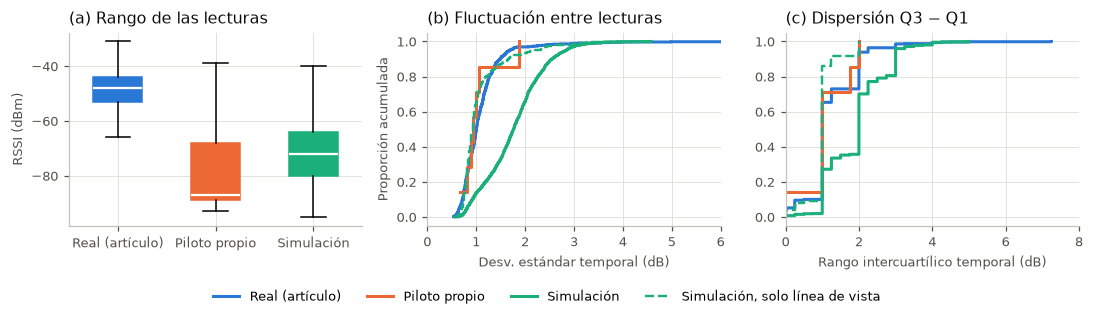

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(10, 2.9))
datos_rango = [real.iloc[:, :8].values.ravel(), piloto.rssi_dbm.values, lect_sim[~np.isnan(lect_sim)]]
bp = ax[0].boxplot(datos_rango, vert=True, widths=0.5, patch_artist=True, showfliers=False,
                   medianprops=dict(color="white", lw=1.5))
for patch, c in zip(bp["boxes"], FUENTE.values()):
    patch.set_facecolor(c); patch.set_edgecolor(c)
ax[0].set_xticks([1, 2, 3], list(FUENTE.keys()))
ax[0].set_ylabel("RSSI (dBm)"); ax[0].set_title("(a) Rango de las lecturas", loc="left", color=TINTA)
for k, (nombre, t) in enumerate(zip(FUENTE, [tmp_real, tmp_pil, tmp_sim])):
    for j, col in enumerate(["de", "iqr"]):
        v = np.sort(t[col].dropna().values)
        ax[j+1].step(v, np.arange(1, len(v)+1) / len(v), where="post", color=FUENTE[nombre], lw=2, label=nombre)
for j, col in enumerate(["de", "iqr"]):
    v = np.sort(tmp_sim.loc[tmp_sim.paredes == 0, col].dropna().values)
    ax[j+1].step(v, np.arange(1, len(v)+1) / len(v), where="post", color=FUENTE["Simulación"], lw=1.6, ls="--",
                 label="Simulación, solo línea de vista")
ax[1].set_xlabel("Desv. estándar temporal (dB)"); ax[1].set_title("(b) Fluctuación entre lecturas", loc="left", color=TINTA)
ax[2].set_xlabel("Rango intercuartílico temporal (dB)"); ax[2].set_title("(c) Dispersión Q3 − Q1", loc="left", color=TINTA)
ax[1].set_ylabel("Proporción acumulada"); ax[1].set_xlim(0, 6); ax[2].set_xlim(0, 8)
h, l = ax[2].get_legend_handles_labels()
fig.tight_layout(rect=(0, 0.1, 1, 1))
fig.legend(h, l, loc="lower center", ncol=4, bbox_to_anchor=(0.5, 0.0))
guardar(fig, "fig2_anclaje"); plt.show()

**Lectura.** La simulación cubre el rango de las mediciones reales y del piloto. **En línea de vista**, que es la condición de la sala del artículo, la fluctuación temporal simulada coincide con la medida (~1 dB). En conjunto es mayor, porque en nuestro piso muchas señales atraviesan muros: ese aumento con las paredes es un supuesto declarado, tomado de la literatura de propagación. La sombra espacial simulada (5 dB) está dentro del rango estimado sobre los datos reales (3.8–6.6 dB), y la autocorrelación lag-1 coincide. El piloto muestra que los APs débiles (< −85 dBm) solo se detectan en parte de los escaneos; con eso calibramos la curva de detección que genera los datos faltantes.

## 3. Consolidación del dataset definitivo
14 jornadas (días) × 18 zonas × 20 visitas = **5 040 instancias balanceadas**. Cada visita reúne 40 lecturas por AP, que se resumen en Q1, Q2 y Q3 (24 predictores).

In [6]:
t0 = time.time()
df, EDIF = generar_dataset(n_dias=14, visitas_por_dia=20, m=40, seed=SEED)
FEATS = columnas("cuartiles")
df.to_csv("datos/dataset_simulado_segunda_entrega.csv", index=False)
print(f"Generado en {time.time()-t0:.1f} s · forma {df.shape}")

X_all = df[FEATS]
falt_ap = {f"AP{a}": X_all[[f"AP{a}_Q1"]].isna().mean().iloc[0] for a in range(1, N_APS+1)}
calidad = {
    "instancias": len(df), "zonas": df.zona.nunique(), "predictores": len(FEATS),
    "instancias_por_zona_min": int(df.zona.value_counts().min()), "instancias_por_zona_max": int(df.zona.value_counts().max()),
    "celdas_faltantes_pct": round(100 * X_all.isna().mean().mean(), 2),
    "filas_con_faltantes_pct": round(100 * X_all.isna().any(axis=1).mean(), 1),
    "faltantes_por_AP_pct": {k: round(100 * v, 1) for k, v in falt_ap.items()},
    "duplicados": int(df.duplicated(subset=FEATS).sum()),
    "rango_dBm": [float(np.nanmin(X_all.values)), float(np.nanmax(X_all.values))],
    "cruces_Q1_gt_Q2_o_Q2_gt_Q3": int(sum(((df[f"AP{a}_Q1"] > df[f"AP{a}_Q2"]) | (df[f"AP{a}_Q2"] > df[f"AP{a}_Q3"])).sum() for a in range(1, 9))),
}
RES["calidad"] = calidad
for k, v in calidad.items(): print(f"{k:32s} {v}")
df[FEATS].describe().T.round(1).head(9)

Generado en 4.7 s · forma (5040, 45)
instancias                       5040
zonas                            18
predictores                      24
instancias_por_zona_min          280
instancias_por_zona_max          280
celdas_faltantes_pct             7.75
filas_con_faltantes_pct          45.4
faltantes_por_AP_pct             {'AP1': np.float64(9.4), 'AP2': np.float64(3.3), 'AP3': np.float64(3.1), 'AP4': np.float64(6.5), 'AP5': np.float64(18.4), 'AP6': np.float64(4.7), 'AP7': np.float64(13.3), 'AP8': np.float64(3.3)}
duplicados                       0
rango_dBm                        [-95.0, -27.0]
cruces_Q1_gt_Q2_o_Q2_gt_Q3       0


,count,mean,std,min,25%,50%,75%,max
AP1_Q1,4565.0,-73.2,11.9,-94.2,-83.0,-73.0,-67.0,-37.0
AP1_Q2,4565.0,-72.3,11.7,-94.0,-82.0,-72.0,-66.0,-36.0
AP1_Q3,4565.0,-71.5,11.5,-92.8,-80.5,-72.0,-65.0,-36.0
AP2_Q1,4876.0,-69.3,10.8,-94.0,-77.2,-69.0,-63.0,-34.0
AP2_Q2,4876.0,-68.5,10.6,-93.5,-76.0,-68.0,-62.0,-33.0
AP2_Q3,4876.0,-67.6,10.4,-93.0,-75.0,-68.0,-61.0,-33.0
AP3_Q1,4884.0,-64.6,12.3,-93.0,-73.0,-65.0,-57.0,-31.0
AP3_Q2,4884.0,-63.8,12.1,-92.0,-72.0,-64.0,-56.0,-30.0
AP3_Q3,4884.0,-63.0,11.9,-91.0,-71.0,-63.0,-55.0,-30.0


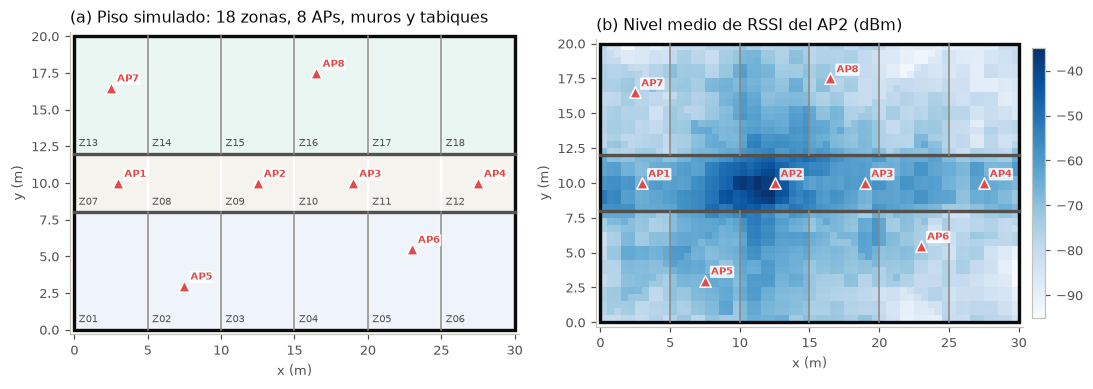

In [7]:
def dibujar_plano(ax, valores=None, cmap=None, vmin=None, vmax=None, fmt="{:.0%}", etiquetas=True):
    tonos = {"Aula": "#eef4fa", "Corredor": "#f4f3ee", "Oficina": "#eaf6f1"}
    for i, (zid, x0, x1, y0, y1, tipo) in enumerate(ZONAS):
        fc = cmap((valores[i] - vmin) / (vmax - vmin)) if valores is not None else tonos[tipo]
        ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, facecolor=fc, edgecolor="white", lw=1.5))
        if etiquetas:
            txt = zid if valores is None else f"{zid}  {fmt.format(valores[i])}"
            oscuro = valores is not None and (valores[i] - vmin) / (vmax - vmin) > 0.55
            ax.text(x0 + 0.3, y0 + 0.35, txt, ha="left", va="bottom", fontsize=6.5,
                    color="white" if oscuro else TINTA2, weight="bold" if valores is not None else "normal")
    for yw in Y_CORREDOR: ax.plot([0, ANCHO], [yw, yw], color=TINTA2, lw=2.2)
    for xw in np.arange(5, ANCHO, 5):
        ax.plot([xw, xw], [0, 8], color=GRIS, lw=1); ax.plot([xw, xw], [12, 20], color=GRIS, lw=1)
    ax.add_patch(Rectangle((0, 0), ANCHO, FONDO, fill=False, edgecolor=TINTA, lw=2.2))
    ax.scatter(APS[:, 0], APS[:, 1], marker="^", s=55, color="#e34948", edgecolor="white", lw=1, zorder=5)
    for i, (x, y) in enumerate(APS):
        ax.annotate(f"AP{i+1}", (x, y), xytext=(4, 4), textcoords="offset points", fontsize=6.5, color="#e34948", weight="bold",
                    bbox=dict(boxstyle="round,pad=0.12", fc="white", ec="none", alpha=0.85))
    ax.set_xlim(-0.3, ANCHO + 0.3); ax.set_ylim(-0.3, FONDO + 0.3); ax.set_aspect("equal"); ax.grid(False)
    ax.set_xlabel("x (m)"); ax.set_ylabel("y (m)")

# Mapa de nivel medio (sin ruido temporal) del AP2 en el corredor
xs = np.arange(0.25, ANCHO, 0.5); ys = np.arange(0.25, FONDO, 0.5)
mapa = np.array([[nivel_medio(EDIF, np.array([x, y]), 1)[0] for x in xs] for y in ys])

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
dibujar_plano(ax[0]); ax[0].set_title("(a) Piso simulado: 18 zonas, 8 APs, muros y tabiques", loc="left", color=TINTA)
im = ax[1].imshow(mapa, origin="lower", extent=[0, ANCHO, 0, FONDO], cmap="Blues", vmin=-95, vmax=-35)
dibujar_plano(ax[1], etiquetas=False)
for p in ax[1].patches[:-1]: p.set_alpha(0)
ax[1].set_title("(b) Nivel medio de RSSI del AP2 (dBm)", loc="left", color=TINTA)
fig.colorbar(im, ax=ax[1], fraction=0.03, pad=0.02)
fig.tight_layout(); guardar(fig, "fig1_plano"); plt.show()

**Calidad y transformaciones necesarias.** No hay duplicados ni incoherencias (Q1 ≤ Q2 ≤ Q3 en todas las filas) y las clases están perfectamente balanceadas (280 por zona), así que **no se requiere balanceo**. Los faltantes se concentran en los APs lejanos o detrás de varios muros (señal bajo la sensibilidad) y en las fallas de AP; se imputan dentro del Pipeline. No hay variables categóricas que codificar. `x`, `y`, `tipo` y `dia` son metadatos y **no** entran al modelo: `x, y` revelarían la zona (fuga directa) y `dia` solo se usa para agrupar la validación.

## 4. Partición por días y verificación empírica de supuestos

**Partición.** Los días 1–10 (3 600 instancias, 71 %) son entrenamiento y los días 11–14 (1 440, 29 %) son prueba. Se conserva la proporción 70/30 prevista en la Fase 1, pero la división se hace **por jornada y no al azar**: en uso real, la huella se calibra unos días y el sistema se usa después. Todo el análisis exploratorio que sigue usa **solo entrenamiento**.

In [8]:
tr, te = df[df.dia <= 10].reset_index(drop=True), df[df.dia > 10].reset_index(drop=True)
Xtr, ytr, gtr = tr[FEATS], tr.zona.values, tr.dia.values
Xte, yte = te[FEATS], te.zona.values
print("Entrenamiento:", Xtr.shape, "| Prueba:", Xte.shape,
      "| por zona en entrenamiento:", pd.Series(ytr).value_counts().unique())

# Para el análisis exploratorio: imputación y estandarización ajustadas SOLO con entrenamiento
prep = Pipeline([("imputar", SimpleImputer(strategy="median")), ("escalar", StandardScaler())]).fit(Xtr)
Ztr = pd.DataFrame(prep.transform(Xtr), columns=FEATS)

# --- Separabilidad ---
F, pF = f_classif(Ztr, ytr)
sil = silhouette_score(Ztr, ytr, random_state=SEED)
cent = Ztr.groupby(ytr).mean()
disp = np.sqrt(Ztr.groupby(ytr).var().mean(axis=1))
pares = []
zs = list(cent.index)
for i in range(len(zs)):
    for j in range(i+1, len(zs)):
        dc = np.linalg.norm(cent.iloc[i] - cent.iloc[j])
        pares.append((zs[i], zs[j], dc / np.sqrt((disp.iloc[i]**2 + disp.iloc[j]**2) / 2) / np.sqrt(len(FEATS))))
pares = sorted(pares, key=lambda t: t[2])
print(f"Silhouette (zonas): {sil:.3f} | F de ANOVA: mín {F.min():.0f}, mediana {np.median(F):.0f}, máx {F.max():.0f} (todas p < 1e-100: {np.all(pF < 1e-100)})")
print("Pares de zonas más cercanos (distancia entre centroides / dispersión intra-zona):")
for a, b, r in pares[:5]: print(f"   {a}–{b}: {r:.2f}")
print("Par más lejano:", pares[-1])
RES["separabilidad"] = dict(silhouette=round(sil, 3), F_min=round(float(F.min()), 1), F_mediana=round(float(np.median(F)), 1),
                            pares_cercanos=[(a, b, round(r, 2)) for a, b, r in pares[:5]], par_lejano=[pares[-1][0], pares[-1][1], round(pares[-1][2], 2)],
                            ratio_mediano=round(float(np.median([p[2] for p in pares])), 2))

Entrenamiento: (3600, 24) | Prueba: (1440, 24) | por zona en entrenamiento: [200]


Silhouette (zonas): 0.206 | F de ANOVA: mín 700, mediana 841, máx 994 (todas p < 1e-100: True)
Pares de zonas más cercanos (distancia entre centroides / dispersión intra-zona):
   Z10–Z11: 0.81
   Z13–Z14: 0.90
   Z16–Z17: 1.04
   Z05–Z06: 1.07
   Z04–Z06: 1.18
Par más lejano: ('Z01', 'Z12', np.float64(4.524919956876153))


In [9]:
# --- ¿Aportan Q1/Q3 información distinta a la mediana? Análogo a la Tabla 2 del artículo ---
medias_z = tr.groupby("zona")[FEATS].mean()
ejemplos = []
for a in range(1, 9):
    q2 = medias_z[f"AP{a}_Q2"]; iqr = medias_z[f"AP{a}_Q3"] - medias_z[f"AP{a}_Q1"]
    for i, zi in enumerate(zs):
        for zj in zs[i+1:]:
            if abs(q2[zi] - q2[zj]) < 0.5:
                ejemplos.append((f"AP{a}", zi, zj, q2[zi] - q2[zj], iqr[zi] - iqr[zj]))
ej = sorted(ejemplos, key=lambda t: -abs(t[4]))[0]
ap_e, z1, z2 = ej[0], ej[1], ej[2]
tabla_q = medias_z.loc[[z1, z2], [f"{ap_e}_Q1", f"{ap_e}_Q2", f"{ap_e}_Q3"]].round(2)
print(f"Ejemplo: {ap_e} en {z1} y {z2} tienen casi la misma mediana pero distinta dispersión")
print(tabla_q)
RES["ejemplo_cuartiles"] = dict(ap=ap_e, zonas=[z1, z2], tabla=tabla_q.values.tolist())

# Dispersión (IQR) y asimetría según el número de paredes entre la zona y el AP
filas = []
for zid, x0, x1, y0, y1, tipo in ZONAS:
    c = np.array([(x0+x1)/2, (y0+y1)/2])
    for a in range(N_APS):
        m, t = paredes_atravesadas(c, APS[a])
        sub = tr[tr.zona == zid]
        filas.append(dict(paredes=min(m+t, 3), iqr=(sub[f"AP{a+1}_Q3"] - sub[f"AP{a+1}_Q1"]).mean(),
                          baja=(sub[f"AP{a+1}_Q2"] - sub[f"AP{a+1}_Q1"]).mean(), alta=(sub[f"AP{a+1}_Q3"] - sub[f"AP{a+1}_Q2"]).mean()))
pw = pd.DataFrame(filas).groupby("paredes").mean().round(2)
pw.index = ["0 (línea de vista)", "1", "2", "3 o más"][:len(pw)]
RES["iqr_por_paredes"] = pw.reset_index().values.tolist()
pw

Ejemplo: AP2 en Z02 y Z12 tienen casi la misma mediana pero distinta dispersión
      AP2_Q1  AP2_Q2  AP2_Q3
zona                        
Z02   -67.41  -66.44  -65.41
Z12   -66.48  -65.95  -65.42


,iqr,baja,alta
0 (línea de vista),1.05,0.52,0.53
1,1.57,0.81,0.76
2,2.04,1.04,1.00
3 o más,2.52,1.28,1.24


In [10]:
# --- Normalidad por clase (habilita NB gaussiano y LDA/QDA) ---
pvals, asim, tipoq = [], [], []
for z in zs:
    sub = Xtr[ytr == z]
    for f in FEATS:
        v = sub[f].dropna().values
        if len(v) >= 20 and v.std() > 0:
            pvals.append(stats.shapiro(v).pvalue); asim.append(stats.skew(v)); tipoq.append(f[-2:])
pvals, asim, tipoq = np.array(pvals), np.array(asim), np.array(tipoq)
rech = np.mean(pvals < 0.05); rech_bh = np.mean(stats.false_discovery_control(pvals) < 0.05)

# --- Independencia condicional (supuesto de Naive Bayes): correlación intra-zona entre cuartiles del mismo AP ---
corr_intra = np.mean([Xtr[ytr == z].corr().values for z in zs], axis=0)
corr_intra = pd.DataFrame(corr_intra, index=FEATS, columns=FEATS)
r_mismo_ap = np.mean([corr_intra.loc[f"AP{a}_{p}", f"AP{a}_{q}"] for a in range(1, 9) for p, q in [("Q1","Q2"),("Q2","Q3"),("Q1","Q3")]])
r_otro_ap = np.mean([corr_intra.loc[f"AP{a}_Q2", f"AP{b}_Q2"] for a in range(1, 9) for b in range(a+1, 9)])

# --- Homocedasticidad entre clases (supuesto de LDA) ---
lev = [stats.levene(*[Xtr.loc[ytr == z, f].dropna().values for z in zs]).pvalue for f in FEATS]
ratio_de = (Xtr.groupby(ytr)[FEATS].std().max() / Xtr.groupby(ytr)[FEATS].std().min()).median()

supuestos = dict(shapiro_rechazo_pct=round(100*rech, 1), shapiro_rechazo_BH_pct=round(100*rech_bh, 1), n_pruebas=len(pvals),
                 asimetria_mediana_Q1=round(float(np.median(asim[tipoq == "Q1"])), 2),
                 asimetria_mediana_Q3=round(float(np.median(asim[tipoq == "Q3"])), 2),
                 corr_intra_mismo_AP=round(float(r_mismo_ap), 2), corr_intra_otro_AP=round(float(r_otro_ap), 2),
                 levene_rechazo_pct=round(100*np.mean(np.array(lev) < 0.05), 1), ratio_DE_max_min_mediano=round(float(ratio_de), 2))
RES["supuestos"] = supuestos
for k, v in supuestos.items(): print(f"{k:30s} {v}")

shapiro_rechazo_pct            85.5
shapiro_rechazo_BH_pct         82.3
n_pruebas                      429
asimetria_mediana_Q1           0.14
asimetria_mediana_Q3           0.12
corr_intra_mismo_AP            0.99
corr_intra_otro_AP             0.04
levene_rechazo_pct             100.0
ratio_DE_max_min_mediano       2.64


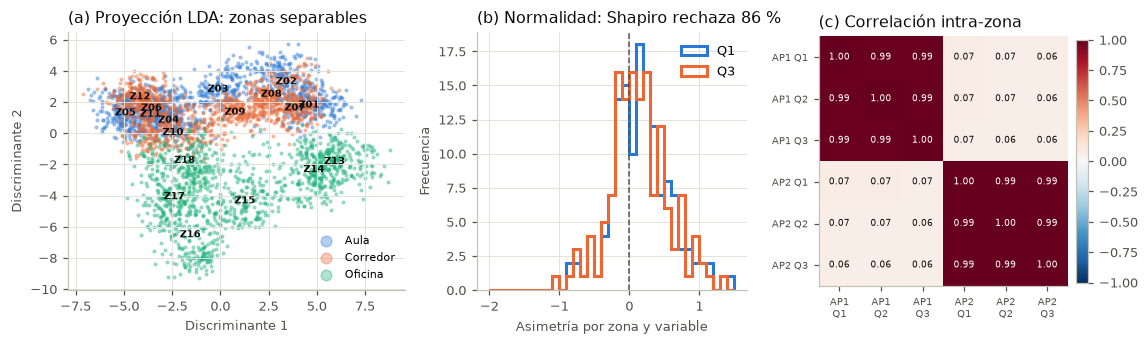

In [11]:
lda_vis = Pipeline([("imputar", SimpleImputer(strategy="median")), ("escalar", StandardScaler()),
                    ("lda", LinearDiscriminantAnalysis(n_components=2))]).fit(Xtr, ytr)
P = lda_vis.transform(Xtr)
fig, ax = plt.subplots(1, 3, figsize=(10.5, 3.2), gridspec_kw=dict(width_ratios=[1.25, 1, 1]))
tipos_tr = tr.tipo.values
for t, c in zip(["Aula", "Corredor", "Oficina"], ["#2a78d6", "#eb6834", "#1baf7a"]):
    ax[0].scatter(P[tipos_tr == t, 0], P[tipos_tr == t, 1], s=3, alpha=0.35, color=c, label=t, rasterized=True)
for z in zs:
    cx, cy = P[ytr == z].mean(axis=0)
    ax[0].text(cx, cy, z, fontsize=6.5, ha="center", va="center", color=TINTA, weight="bold")
ax[0].set_xlabel("Discriminante 1"); ax[0].set_ylabel("Discriminante 2")
ax[0].legend(markerscale=4, loc="best", fontsize=7); ax[0].set_title("(a) Proyección LDA: zonas separables", loc="left", color=TINTA)

bins = np.linspace(-2, 1.5, 36)
ax[1].hist(asim[tipoq == "Q1"], bins=bins, color="#2a78d6", histtype="step", lw=2, label="Q1")
ax[1].hist(asim[tipoq == "Q3"], bins=bins, color="#eb6834", histtype="step", lw=2, label="Q3")
ax[1].axvline(0, color=TINTA2, lw=1, ls="--")
ax[1].set_xlabel("Asimetría por zona y variable"); ax[1].set_ylabel("Frecuencia"); ax[1].legend()
ax[1].set_title(f"(b) Normalidad: Shapiro rechaza {100*rech:.0f} %", loc="left", color=TINTA)

blk = [f"AP{a}_{q}" for a in (1, 2) for q in ("Q1", "Q2", "Q3")]
im = ax[2].imshow(corr_intra.loc[blk, blk].values, cmap="RdBu_r", vmin=-1, vmax=1)
ax[2].set_xticks(range(6), [b.replace("_", "\n") for b in blk], fontsize=6.5)
ax[2].set_yticks(range(6), [b.replace("_", " ") for b in blk], fontsize=6.5)
for i in range(6):
    for j in range(6):
        v = corr_intra.loc[blk[i], blk[j]]
        ax[2].text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6, color="white" if abs(v) > 0.6 else TINTA)
ax[2].grid(False); ax[2].set_title("(c) Correlación intra-zona", loc="left", color=TINTA)
fig.colorbar(im, ax=ax[2], fraction=0.045, pad=0.03)
fig.tight_layout(); guardar(fig, "fig3_supuestos"); plt.show()

**Lectura de los supuestos (documentados, como pidió la retroalimentación).**
* **Separabilidad: se cumple.** Todas las variables discriminan entre zonas (ANOVA F muy alto) y la proyección LDA separa las 18 zonas en grupos reconocibles. Los pares más cercanos son zonas **contiguas**, y ahí se concentrarán los errores.
* **Normalidad por clase: se cumple solo de forma aproximada.** Shapiro-Wilk rechaza la normalidad en la mayoría de las combinaciones zona×variable. Hay dos causas: la discretización (las lecturas son dBm enteros, así que los cuartiles saltan de 0.25 en 0.25 dB) y la mezcla de posiciones dentro de cada zona. Aun así, las distribuciones son casi simétricas (asimetría mediana ≈ 0.1), por lo que NB gaussiano y LDA/QDA son aproximaciones razonables, no modelos «correctos».
* **Independencia condicional (Naive Bayes): no se cumple.** Q1, Q2 y Q3 de un mismo AP están casi perfectamente correlacionados dentro de cada zona, así que NB cuenta tres veces la misma evidencia.
* **Covarianzas iguales entre clases (LDA): no se cumple.** Levene rechaza en la mayoría de variables, porque la dispersión depende de cuántas paredes hay entre la zona y el AP. Esto favorece a QDA (o a una LDA regularizada) sobre la LDA pura.

## 5. Flujo reproducible sin fuga de datos

Orden de las etapas y por qué previene la fuga:

1. **Extracción de cuartiles (por instancia).** Cada fila se calcula solo con sus propias 40 lecturas; no usa información de otras filas. Por eso puede hacerse antes de partir, sin fuga.
2. **Partición por días.** Prueba = días 11–14, que no se tocan hasta el final.
3. **Dentro de cada pliegue de validación cruzada (Pipeline):**
   `SimpleImputer(mediana)` → `StandardScaler` → modelo. La mediana de imputación y la media/desviación de escalamiento se **ajustan solo con el pliegue de entrenamiento** y se aplican sin reajustar al de validación.
4. **Validación cruzada agrupada por día (`GroupKFold`, 5 pliegues de 2 días).** Las visitas de un mismo día comparten la deriva diaria. Si quedaran repartidas entre entrenamiento y validación, el modelo «reconocería el día» y el desempeño se sobrestimaría.
5. **Sin balanceo ni selección supervisada de variables:** las clases ya están balanceadas. La selección de APs del barrido n×k se fija por diseño (AP1…APn), no con los datos.

In [12]:
def pipe(modelo, escalar=True):
    return Pipeline([("imputar", SimpleImputer(strategy="median")),
                     ("escalar", StandardScaler() if escalar else "passthrough"),
                     ("modelo", modelo)])

def error_medio_m(y_true, y_pred):
    a = CENTROS[[ZONA_IDX[z] for z in y_true]]; b = CENTROS[[ZONA_IDX[z] for z in y_pred]]
    return float(np.linalg.norm(a - b, axis=1).mean())

def errores_m(y_true, y_pred):
    return np.linalg.norm(CENTROS[[ZONA_IDX[z] for z in y_true]] - CENTROS[[ZONA_IDX[z] for z in y_pred]], axis=1)

SCORING = {"accuracy": "accuracy", "f1_macro": "f1_macro",
           "error_m": make_scorer(error_medio_m, greater_is_better=False)}
CV = GroupKFold(n_splits=5)

# Demostración: efecto de la estrategia de validación sobre la estimación (kNN k=7)
knn_demo = pipe(KNeighborsClassifier(n_neighbors=7))
cv_grupo = cross_val_score(knn_demo, Xtr, ytr, groups=gtr, cv=CV)
cv_azar = cross_val_score(knn_demo, Xtr, ytr, cv=StratifiedKFold(5, shuffle=True, random_state=SEED))
# Fuga clásica: imputar y escalar con TODO el entrenamiento antes de la validación cruzada
Z_fuga = StandardScaler().fit_transform(SimpleImputer(strategy="median").fit_transform(Xtr))
cv_fuga = cross_val_score(KNeighborsClassifier(n_neighbors=7), Z_fuga, ytr, groups=gtr, cv=CV)
acc_te_demo = accuracy_score(yte, knn_demo.fit(Xtr, ytr).predict(Xte))
RES["fuga_demo"] = dict(cv_grupo=[round(cv_grupo.mean(), 4), round(cv_grupo.std(), 4)],
                        cv_azar=[round(cv_azar.mean(), 4), round(cv_azar.std(), 4)],
                        cv_preproceso_fuera=[round(cv_fuga.mean(), 4), round(cv_fuga.std(), 4)],
                        prueba_dias_nuevos=round(acc_te_demo, 4))
print(json.dumps(RES["fuga_demo"], indent=1))

{
 "cv_grupo": [
  0.9411,
  0.0134
 ],
 "cv_azar": [
  0.9456,
  0.0091
 ],
 "cv_preproceso_fuera": [
  0.9417,
  0.0132
 ],
 "prueba_dias_nuevos": 0.9493
}


## 6. Ajuste de hiperparámetros y comparación de modelos
`GridSearchCV` con `GroupKFold` por días. La métrica de selección (`refit`) es el **accuracy**, válido porque las clases están balanceadas. También se registran **F1-macro**, que detecta zonas sistemáticamente mal clasificadas, y el **error medio de localización en metros (ME)**, la métrica del artículo, que penaliza más confundir zonas lejanas que zonas contiguas.

In [13]:
MODELOS = {
    "Línea base": (pipe(DummyClassifier(strategy="most_frequent"), escalar=False), {}),
    "kNN": (pipe(KNeighborsClassifier()),
            {"escalar": [StandardScaler(), "passthrough"], "modelo__n_neighbors": list(range(1, 26, 2)),
             "modelo__weights": ["uniform", "distance"], "modelo__p": [1, 2]}),
    "Naive Bayes": (pipe(GaussianNB(), escalar=False), {"modelo__var_smoothing": list(np.logspace(-9, -1, 9))}),
    "Regresión logística": (pipe(LogisticRegression(max_iter=5000)), {"modelo__C": list(np.logspace(-3, 2, 6))}),
    "LDA": (pipe(LinearDiscriminantAnalysis(solver="lsqr")), {"modelo__shrinkage": [None, "auto", 0.05, 0.1, 0.2, 0.4]}),
    "QDA": (pipe(QuadraticDiscriminantAnalysis()), {"modelo__reg_param": [0.0, 0.01, 0.05, 0.1, 0.2, 0.4]}),
}
BUSQ, filas_cv = {}, []
for nombre, (modelo, grid) in MODELOS.items():
    t0 = time.time()
    gs = GridSearchCV(modelo, grid, scoring=SCORING, refit="accuracy", cv=CV, n_jobs=1)
    gs.fit(Xtr, ytr, groups=gtr)
    BUSQ[nombre] = gs
    r, i = gs.cv_results_, gs.best_index_
    folds = [r[f"split{k}_test_accuracy"][i] for k in range(5)]
    params = {k.replace("modelo__", ""): (type(v).__name__ if k == "escalar" and v != "passthrough"
                                          else float(v) if isinstance(v, np.floating) else v)
              for k, v in gs.best_params_.items()}
    filas_cv.append(dict(Modelo=nombre, configs=len(r["params"]), mejores=params,
                         acc=r["mean_test_accuracy"][i], acc_sd=r["std_test_accuracy"][i],
                         f1=r["mean_test_f1_macro"][i], f1_sd=r["std_test_f1_macro"][i],
                         me=-r["mean_test_error_m"][i], me_sd=r["std_test_error_m"][i],
                         folds=folds, seg=time.time() - t0))
    print(f"{nombre:20s} acc CV = {r['mean_test_accuracy'][i]:.3f} ± {r['std_test_accuracy'][i]:.3f}  ({time.time()-t0:.0f} s)  {params}")
tabla_cv = pd.DataFrame(filas_cv)

Línea base           acc CV = 0.056 ± 0.000  (0 s)  {}


kNN                  acc CV = 0.960 ± 0.013  (13 s)  {'escalar': 'passthrough', 'n_neighbors': 1, 'p': 1, 'weights': 'uniform'}


Naive Bayes          acc CV = 0.909 ± 0.010  (1 s)  {'var_smoothing': 0.01}


Regresión logística  acc CV = 0.918 ± 0.013  (5 s)  {'C': 10.0}


LDA                  acc CV = 0.909 ± 0.013  (1 s)  {'shrinkage': None}


QDA                  acc CV = 0.934 ± 0.008  (1 s)  {'reg_param': 0.01}


In [14]:
# Barrido de k (validación) para la mejor configuración de escalamiento/pesos/distancia de kNN
r = pd.DataFrame(BUSQ["kNN"].cv_results_)
bp_ = BUSQ["kNN"].best_params_
mask = (r.param_modelo__weights == bp_["modelo__weights"]) & (r.param_modelo__p == bp_["modelo__p"]) & \
       (r.param_escalar.astype(str) == str(bp_["escalar"]))
curva_k = r[mask].sort_values("param_modelo__n_neighbors")[["param_modelo__n_neighbors", "mean_test_accuracy", "std_test_accuracy", "mean_test_error_m"]]
curva_k.columns = ["k", "acc", "acc_sd", "me"]; curva_k["me"] = -curva_k["me"]
# Efecto del escalamiento y de la ponderación (mejor k de cada combinación)
efectos = r.groupby([r.param_escalar.astype(str).str.slice(0, 14), "param_modelo__weights", "param_modelo__p"]).mean_test_accuracy.max().round(4)
RES["knn_curva_k"] = curva_k.round(4).values.tolist()
RES["knn_efectos"] = {" | ".join(map(str, k)): v for k, v in efectos.items()}
print(curva_k.round(4).to_string(index=False)); print(efectos)

 k    acc  acc_sd     me
 1 0.9603  0.0129 0.2452
 3 0.9528  0.0138 0.2947
 5 0.9508  0.0180 0.2990
 7 0.9478  0.0157 0.3159
 9 0.9447  0.0130 0.3309
11 0.9403  0.0121 0.3628
13 0.9381  0.0136 0.3682
15 0.9367  0.0133 0.3780
17 0.9322  0.0143 0.4032
19 0.9339  0.0138 0.3907
21 0.9361  0.0145 0.3809
23 0.9303  0.0158 0.4170
25 0.9319  0.0161 0.4123
param_escalar   param_modelo__weights  param_modelo__p
StandardScaler  distance               1                  0.9586
                                       2                  0.9558
                uniform                1                  0.9586
                                       2                  0.9558
passthrough     distance               1                  0.9603
                                       2                  0.9553
                uniform                1                  0.9603
                                       2                  0.9553
Name: mean_test_accuracy, dtype: float64


## 7. Evaluación final en el conjunto de prueba (días 11–14), con variabilidad

In [15]:
def bootstrap(y, yp, fn, B=1000, seed=SEED):
    rng = np.random.default_rng(seed); n = len(y)
    vals = [fn(y[idx], yp[idx]) for idx in (rng.integers(0, n, n) for _ in range(B))]
    return np.percentile(vals, [2.5, 97.5])

PRED, filas_te = {}, []
for nombre, gs in BUSQ.items():
    yp = gs.best_estimator_.predict(Xte); PRED[nombre] = yp
    e = errores_m(yte, yp)
    por_dia = [accuracy_score(yte[te.dia == d], yp[te.dia == d]) for d in sorted(te.dia.unique())]
    filas_te.append(dict(Modelo=nombre, acc_te=accuracy_score(yte, yp), acc_ic=bootstrap(yte, yp, accuracy_score),
                         f1_te=f1_score(yte, yp, average="macro"), me_te=e.mean(), me_ic=bootstrap(yte, yp, error_medio_m),
                         p90=np.percentile(e, 90), acc_dia_min=min(por_dia), acc_dia_max=max(por_dia)))
tabla_te = pd.DataFrame(filas_te)
resumen = tabla_cv.merge(tabla_te, on="Modelo")
pd.set_option("display.width", 200)
vista = pd.DataFrame({
    "Modelo": resumen.Modelo,
    "Mejores hiperparámetros": resumen.mejores.astype(str),
    "Accuracy CV": [f"{a:.3f} ± {s:.3f}" for a, s in zip(resumen.acc, resumen.acc_sd)],
    "F1-macro CV": [f"{a:.3f} ± {s:.3f}" for a, s in zip(resumen.f1, resumen.f1_sd)],
    "ME CV (m)": [f"{a:.2f} ± {s:.2f}" for a, s in zip(resumen.me, resumen.me_sd)],
    "Accuracy prueba [IC 95 %]": [f"{a:.3f} [{i[0]:.3f}, {i[1]:.3f}]" for a, i in zip(resumen.acc_te, resumen.acc_ic)],
    "ME prueba (m) [IC 95 %]": [f"{a:.2f} [{i[0]:.2f}, {i[1]:.2f}]" for a, i in zip(resumen.me_te, resumen.me_ic)],
    "F1 prueba": resumen.f1_te.round(3), "P90 error (m)": resumen.p90.round(2),
})
orden = resumen.sort_values("acc", ascending=False).Modelo.tolist()
MEJOR, SEGUNDO = orden[0], orden[1]

# McNemar exacto entre el mejor y el segundo modelo en prueba
a_ok, b_ok = PRED[MEJOR] == yte, PRED[SEGUNDO] == yte
n01, n10 = int(np.sum(a_ok & ~b_ok)), int(np.sum(~a_ok & b_ok))
p_mcn = stats.binomtest(n01, n01 + n10, 0.5).pvalue if n01 + n10 > 0 else 1.0
RES["comparacion"] = [{k: (v.tolist() if isinstance(v, np.ndarray) else v) for k, v in fila.items()}
                      for fila in resumen.drop(columns=["folds"]).to_dict(orient="records")]
RES["mejor"], RES["segundo"] = MEJOR, SEGUNDO
RES["mcnemar"] = dict(mejor_acierta_segundo_falla=n01, segundo_acierta_mejor_falla=n10, p=float(p_mcn))
print("Mejor por CV:", MEJOR, "| segundo:", SEGUNDO, "| McNemar:", RES["mcnemar"])
vista

Mejor por CV: kNN | segundo: QDA | McNemar: {'mejor_acierta_segundo_falla': 59, 'segundo_acierta_mejor_falla': 27, 'p': 0.0007317100653124087}


,Modelo,Mejores hiperparámetros,Accuracy CV,F1-macro CV,ME CV (m),Accuracy prueba [IC 95 %],ME prueba (m) [IC 95 %],F1 prueba,P90 error (m)
0,Línea base,{},0.056 ± 0.000,0.006 ± 0.000,15.23 ± 0.00,"0.056 [0.044, 0.067]","15.23 [14.86, 15.62]",0.006,25.71
1,kNN,"{'escalar': 'passthrough', 'n_neighbors': 1, '...",0.960 ± 0.013,0.960 ± 0.013,0.25 ± 0.08,"0.964 [0.954, 0.973]","0.22 [0.16, 0.28]",0.964,0.00
2,Naive Bayes,{'var_smoothing': 0.01},0.909 ± 0.010,0.908 ± 0.010,0.54 ± 0.07,"0.900 [0.883, 0.915]","0.59 [0.49, 0.69]",0.899,0.50
3,Regresión logística,{'C': 10.0},0.918 ± 0.013,0.917 ± 0.013,0.48 ± 0.07,"0.924 [0.910, 0.937]","0.47 [0.38, 0.57]",0.923,0.00
4,LDA,{'shrinkage': None},0.909 ± 0.013,0.908 ± 0.013,0.54 ± 0.09,"0.901 [0.885, 0.915]","0.58 [0.48, 0.68]",0.899,0.00
5,QDA,{'reg_param': 0.01},0.934 ± 0.008,0.933 ± 0.008,0.40 ± 0.07,"0.942 [0.928, 0.954]","0.38 [0.29, 0.47]",0.941,0.00


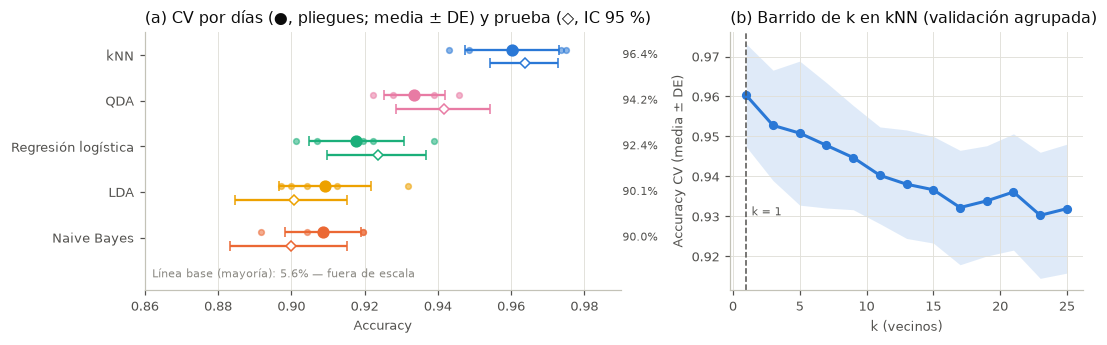

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2), gridspec_kw=dict(width_ratios=[1.35, 1]))
nombres = [n for n in resumen.sort_values("acc").Modelo.tolist() if n != "Línea base"]
for i, n in enumerate(nombres):
    fila = resumen[resumen.Modelo == n].iloc[0]
    ax[0].scatter(fila.folds, [i + 0.12] * 5, s=14, color=COL[n], alpha=0.55, zorder=3)
    ax[0].errorbar(fila.acc, i + 0.12, xerr=fila.acc_sd, fmt="o", ms=7, color=COL[n], capsize=3, zorder=4)
    ax[0].errorbar(fila.acc_te, i - 0.18, xerr=[[fila.acc_te - fila.acc_ic[0]], [fila.acc_ic[1] - fila.acc_te]],
                   fmt="D", ms=5, mfc="white", color=COL[n], capsize=3, zorder=4)
    ax[0].text(1.003, i, f"{fila.acc_te:.1%}", va="center", fontsize=7.5, color=TINTA2, transform=ax[0].get_yaxis_transform())
ax[0].set_yticks(range(len(nombres)), nombres); ax[0].set_xlabel("Accuracy")
ax[0].set_xlim(0.86, 0.99); ax[0].grid(axis="y", visible=False)
base = resumen[resumen.Modelo == "Línea base"].iloc[0]
ax[0].text(0.862, -0.8, f"Línea base (mayoría): {base.acc_te:.1%} — fuera de escala", fontsize=7, color=GRIS, va="center")
ax[0].set_ylim(-1.15, len(nombres) - 0.5)
ax[0].set_title("(a) CV por días (●, pliegues; media ± DE) y prueba (◇, IC 95 %)", loc="left", color=TINTA)

ax[1].fill_between(curva_k.k, curva_k.acc - curva_k.acc_sd, curva_k.acc + curva_k.acc_sd, color=COL["kNN"], alpha=0.15, lw=0)
ax[1].plot(curva_k.k, curva_k.acc, "o-", color=COL["kNN"], lw=2, ms=5)
kb = BUSQ["kNN"].best_params_["modelo__n_neighbors"]
ax[1].axvline(kb, color=TINTA2, ls="--", lw=1); ax[1].text(kb + 0.4, curva_k.acc.min(), f"k = {kb}", fontsize=7.5, color=TINTA2)
ax[1].set_xlabel("k (vecinos)"); ax[1].set_ylabel("Accuracy CV (media ± DE)")
ax[1].set_title("(b) Barrido de k en kNN (validación agrupada)", loc="left", color=TINTA)
fig.tight_layout(); guardar(fig, "fig4_comparacion"); plt.show()

## 8. Reproducción de los objetivos del artículo
**8.1 Barrido del número de APs (n) y de k (Tabla 3 del artículo: n = 2…8, k = 1…13 impares)** con kNN en la configuración del artículo (distancia euclidiana, voto mayoritario = Método I).

In [17]:
esc_best = BUSQ["kNN"].best_params_["escalar"]
barr = []
for n in range(2, 9):
    cols = columnas("cuartiles", range(1, n + 1))
    for k in range(1, 14, 2):
        m = Pipeline([("imputar", SimpleImputer(strategy="median")),
                      ("escalar", StandardScaler() if esc_best != "passthrough" else "passthrough"),
                      ("modelo", KNeighborsClassifier(n_neighbors=k))])
        s = cross_validate(m, tr[cols], ytr, groups=gtr, cv=CV, scoring=SCORING)
        barr.append(dict(n=n, k=k, acc=s["test_accuracy"].mean(), me=-s["test_error_m"].mean()))
barr = pd.DataFrame(barr)
RES["barrido_nk"] = barr.round(4).values.tolist()
print(barr.pivot(index="n", columns="k", values="acc").round(3))

k     1      3      5      7      9      11     13
n                                                 
2  0.416  0.428  0.448  0.455  0.462  0.465  0.468
3  0.604  0.623  0.625  0.641  0.640  0.638  0.636
4  0.723  0.739  0.749  0.747  0.744  0.738  0.732
5  0.826  0.831  0.829  0.822  0.820  0.816  0.811
6  0.916  0.910  0.903  0.898  0.893  0.890  0.889
7  0.940  0.935  0.927  0.926  0.924  0.922  0.916
8  0.955  0.949  0.945  0.940  0.936  0.931  0.929


**8.2 ¿Mejoran los cuartiles frente a representaciones más simples?** Se compara la lectura cruda única (como en los trabajos previos que el artículo critica), la media, la mediana y los tres cuartiles, con distintos números de APs.

In [18]:
reps = {"Lectura cruda": "cruda", "Media": "media", "Mediana (Q2)": "mediana", "Cuartiles Q1–Q3": "cuartiles"}
k_best = BUSQ["kNN"].best_params_["modelo__n_neighbors"]
rep_res = []
for n in [2, 3, 4, 6, 8]:
    for etiqueta, rep in reps.items():
        s = cross_val_score(pipe(KNeighborsClassifier(n_neighbors=k_best)), tr[columnas(rep, range(1, n + 1))], ytr, groups=gtr, cv=CV)
        rep_res.append(dict(n=n, rep=etiqueta, acc=s.mean(), sd=s.std(), folds=s))
rep_res = pd.DataFrame(rep_res)
# Diferencia pareada cuartiles − media por pliegue
dif = {n: (rep_res[(rep_res.n == n) & (rep_res.rep == "Cuartiles Q1–Q3")].folds.iloc[0] -
           rep_res[(rep_res.n == n) & (rep_res.rep == "Media")].folds.iloc[0]) for n in [2, 3, 4, 6, 8]}
RES["representaciones_sim"] = rep_res.drop(columns="folds").round(4).values.tolist()
RES["dif_cuartiles_menos_media"] = {n: [round(d.mean(), 4), round(d.std(), 4)] for n, d in dif.items()}
print(rep_res.pivot(index="n", columns="rep", values="acc").round(3))
print("Cuartiles − media (media ± DE por pliegue):", RES["dif_cuartiles_menos_media"])

rep  Cuartiles Q1–Q3  Lectura cruda  Media  Mediana (Q2)
n                                                       
2              0.419          0.332  0.387         0.381
3              0.603          0.494  0.595         0.607
4              0.722          0.604  0.718         0.719
6              0.916          0.805  0.916         0.915
8              0.956          0.889  0.956         0.954
Cuartiles − media (media ± DE por pliegue): {2: [np.float64(0.0322), np.float64(0.0154)], 3: [np.float64(0.0083), np.float64(0.0146)], 4: [np.float64(0.0042), np.float64(0.0142)], 6: [np.float64(0.0003), np.float64(0.002)], 8: [np.float64(-0.0003), np.float64(0.0027)]}


**8.3 El mismo flujo sobre los datos reales del artículo** (instancias de 10 lecturas consecutivas, validación agrupada por bloque temporal, kNN con k = 1 como en el mejor resultado del artículo).

In [19]:
def instancias_reales(m=10):
    filas = []
    for rp in range(1, 17):
        v = real[real.rp == rp].iloc[:, :8].values.astype(float)
        for b in range(len(v) // m):
            w = v[b*m:(b+1)*m]; f = {"rp": rp, "bloque": b}
            for a in range(8):
                q = np.percentile(w[:, a], [25, 50, 75])
                f.update({f"AP{a+1}_Q1": q[0], f"AP{a+1}_Q2": q[1], f"AP{a+1}_Q3": q[2],
                          f"AP{a+1}_media": w[:, a].mean(), f"AP{a+1}_cruda": w[0, a]})
            filas.append(f)
    return pd.DataFrame(filas)
R = instancias_reales(10)
real_res = []
for n in [2, 3, 4, 8]:
    for etiqueta, rep in reps.items():
        s = cross_validate(pipe(KNeighborsClassifier(n_neighbors=1)), R[columnas(rep, range(1, n + 1))], R.rp.values,
                           groups=R.bloque.values, cv=GroupKFold(5), scoring="accuracy")
        real_res.append(dict(n=n, rep=etiqueta, acc=s["test_score"].mean(), sd=s["test_score"].std()))
real_res = pd.DataFrame(real_res)
RES["representaciones_real"] = real_res.round(4).values.tolist()
RES["real_instancias"] = len(R)
print(len(R), "instancias reales"); print(real_res.pivot(index="n", columns="rep", values="acc").round(3))

352 instancias reales
rep  Cuartiles Q1–Q3  Lectura cruda  Media  Mediana (Q2)
n                                                       
2              0.958          0.720  0.957         0.934
3              0.967          0.829  0.987         0.966
4              1.000          0.946  1.000         1.000
8              1.000          0.997  1.000         1.000


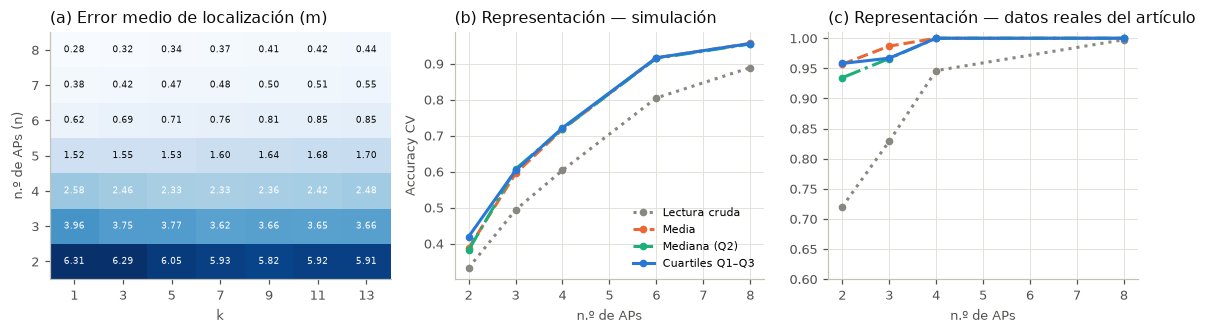

In [20]:
fig, ax = plt.subplots(1, 3, figsize=(10.5, 3.1), gridspec_kw=dict(width_ratios=[1.1, 1, 1]))
piv = barr.pivot(index="n", columns="k", values="me")
im = ax[0].imshow(piv.values, cmap="Blues", aspect="auto", origin="lower")
ax[0].set_xticks(range(piv.shape[1]), piv.columns); ax[0].set_yticks(range(piv.shape[0]), piv.index)
for i in range(piv.shape[0]):
    for j in range(piv.shape[1]):
        v = piv.values[i, j]
        ax[0].text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6, color="white" if v > piv.values.mean() else TINTA)
ax[0].set_xlabel("k"); ax[0].set_ylabel("n.º de APs (n)"); ax[0].grid(False)
ax[0].set_title("(a) Error medio de localización (m)", loc="left", color=TINTA)
estilos = {"Lectura cruda": ("#898781", ":"), "Media": ("#eb6834", "--"), "Mediana (Q2)": ("#1baf7a", "-."), "Cuartiles Q1–Q3": ("#2a78d6", "-")}
for etiqueta, (c, ls) in estilos.items():
    s = rep_res[rep_res.rep == etiqueta]
    ax[1].plot(s.n, s.acc, ls, marker="o", ms=4, color=c, lw=2, label=etiqueta)
    s2 = real_res[real_res.rep == etiqueta]
    ax[2].plot(s2.n, s2.acc, ls, marker="o", ms=4, color=c, lw=2, label=etiqueta)
ax[1].set_xlabel("n.º de APs"); ax[1].set_ylabel("Accuracy CV"); ax[1].legend(fontsize=7)
ax[1].set_title("(b) Representación — simulación", loc="left", color=TINTA)
ax[2].set_xlabel("n.º de APs"); ax[2].set_ylim(0.6, 1.01)
ax[2].set_title("(c) Representación — datos reales del artículo", loc="left", color=TINTA)
fig.tight_layout(); guardar(fig, "fig5_articulo"); plt.show()

## 9. Interpretación preliminar del mejor modelo

In [21]:
mejor_est = BUSQ[MEJOR].best_estimator_
yp = PRED[MEJOR]
recall_z = np.array([np.mean(yp[yte == z] == z) for z, *_ in ZONAS])
e = errores_m(yte, yp)
err = yp != yte
d_err = e[err]
contiguo = np.mean(d_err <= 6.01) if err.any() else 0
# Importancia por permutación agrupada (sobre prueba): por AP y por tipo de cuartil
def imp_permutacion(modelo, X, y, grupos, n_rep=20, seed=SEED):
    rng = np.random.default_rng(seed); base = accuracy_score(y, modelo.predict(X)); out = {}
    for nombre, cols in grupos.items():
        caidas = []
        for _ in range(n_rep):
            Xp = X.copy(); Xp[cols] = X[cols].values[rng.permutation(len(X))]
            caidas.append(base - accuracy_score(y, modelo.predict(Xp)))
        out[nombre] = (float(np.mean(caidas)), float(np.std(caidas)))
    return out
imp_ap = imp_permutacion(mejor_est, Xte, yte, {f"AP{a}": [f"AP{a}_Q1", f"AP{a}_Q2", f"AP{a}_Q3"] for a in range(1, 9)})
imp_q = imp_permutacion(mejor_est, Xte, yte, {q: [f"AP{a}_{q}" for a in range(1, 9)] for q in ("Q1", "Q2", "Q3")})
# Errores por tipo de zona
acc_tipo = te.assign(ok=~err).groupby("tipo").ok.mean()
# Pares más confundidos
cm = confusion_matrix(yte, yp, labels=[z[0] for z in ZONAS])
conf = sorted([(ZONAS[i][0], ZONAS[j][0], cm[i, j]) for i in range(18) for j in range(18) if i != j], key=lambda t: -t[2])[:5]
RES["interpretacion"] = dict(modelo=MEJOR, recall_por_zona={z[0]: round(float(r), 3) for z, r in zip(ZONAS, recall_z)},
                             pct_errores_contiguos=round(100 * contiguo, 1), error_medio_si_falla=round(float(d_err.mean()), 2) if err.any() else 0,
                             importancia_AP=imp_ap, importancia_cuartil=imp_q, acc_por_tipo=acc_tipo.round(3).to_dict(),
                             pares_confundidos=[(a, b, int(c)) for a, b, c in conf])
print(json.dumps(RES["interpretacion"], indent=1, ensure_ascii=False))

{
 "modelo": "kNN",
 "recall_por_zona": {
  "Z01": 1.0,
  "Z02": 1.0,
  "Z03": 0.963,
  "Z04": 0.963,
  "Z05": 0.925,
  "Z06": 0.975,
  "Z07": 0.975,
  "Z08": 0.925,
  "Z09": 0.975,
  "Z10": 0.938,
  "Z11": 0.925,
  "Z12": 1.0,
  "Z13": 1.0,
  "Z14": 1.0,
  "Z15": 0.988,
  "Z16": 0.925,
  "Z17": 0.875,
  "Z18": 1.0
 },
 "pct_errores_contiguos": 82.7,
 "error_medio_si_falla": 6.06,
 "importancia_AP": {
  "AP1": [
   0.11017361111111112,
   0.006361941206148787
  ],
  "AP2": [
   0.08083333333333335,
   0.005740834079289003
  ],
  "AP3": [
   0.08697916666666669,
   0.006539863958971283
  ],
  "AP4": [
   0.09065972222222222,
   0.005005181535847621
  ],
  "AP5": [
   0.08663194444444448,
   0.004688785831871651
  ],
  "AP6": [
   0.11701388888888893,
   0.006131201194416922
  ],
  "AP7": [
   0.10993055555555557,
   0.007166922368392728
  ],
  "AP8": [
   0.11645833333333336,
   0.005017811638750017
  ]
 },
 "importancia_cuartil": {
  "Q1": [
   0.03982638888888888,
   0.003754337768945

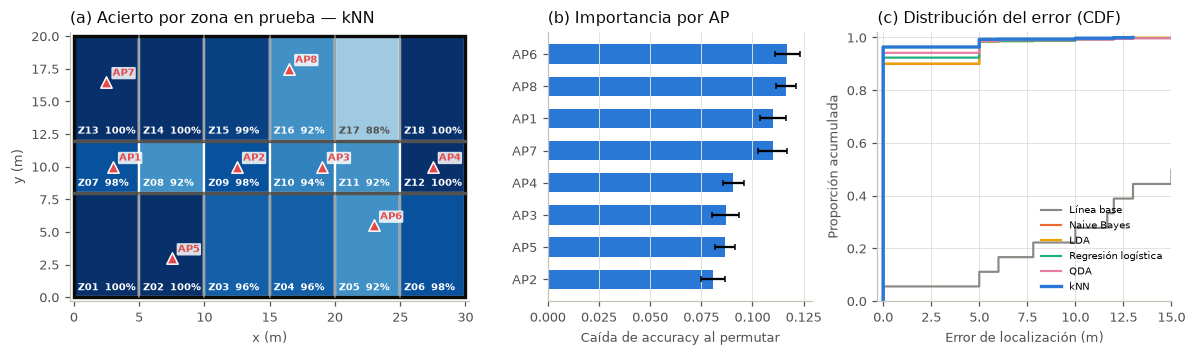

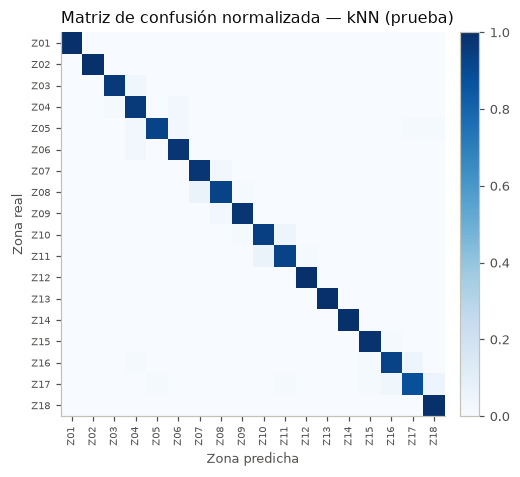

In [22]:
fig, ax = plt.subplots(1, 3, figsize=(11, 3.3), gridspec_kw=dict(width_ratios=[1.45, 0.9, 1]))
dibujar_plano(ax[0], valores=recall_z, cmap=plt.get_cmap("Blues"), vmin=0.80, vmax=1.0)
ax[0].set_title(f"(a) Acierto por zona en prueba — {MEJOR}", loc="left", color=TINTA)
orden_ap = sorted(imp_ap, key=lambda k: imp_ap[k][0])
ax[1].barh(orden_ap, [imp_ap[k][0] for k in orden_ap], xerr=[imp_ap[k][1] for k in orden_ap], color=COL["kNN"] if MEJOR == "kNN" else COL[MEJOR], height=0.6, capsize=2)
ax[1].set_xlabel("Caída de accuracy al permutar"); ax[1].set_title("(b) Importancia por AP", loc="left", color=TINTA)
ax[1].grid(axis="y", visible=False)
for n in orden[::-1]:
    v = np.sort(errores_m(yte, PRED[n]))
    ax[2].step(v, np.arange(1, len(v) + 1) / len(v), where="post", color=COL[n], lw=2.2 if n == MEJOR else 1.4, label=n)
ax[2].set_xlabel("Error de localización (m)"); ax[2].set_ylabel("Proporción acumulada")
ax[2].set_xlim(-0.3, 15); ax[2].set_ylim(0, 1.02); ax[2].legend(fontsize=6.5, loc="lower right")
ax[2].set_title("(c) Distribución del error (CDF)", loc="left", color=TINTA)
fig.tight_layout(); guardar(fig, "fig6_interpretacion"); plt.show()

fig, ax = plt.subplots(figsize=(5.2, 4.4))
cmn = cm / cm.sum(axis=1, keepdims=True)
im = ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(18), [z[0] for z in ZONAS], rotation=90, fontsize=6.5); ax.set_yticks(range(18), [z[0] for z in ZONAS], fontsize=6.5)
ax.set_xlabel("Zona predicha"); ax.set_ylabel("Zona real"); ax.grid(False)
ax.set_title(f"Matriz de confusión normalizada — {MEJOR} (prueba)", loc="left", color=TINTA)
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)
fig.tight_layout(); guardar(fig, "fig7_confusion"); plt.show()

In [23]:
def a_json(o):
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, np.ndarray): return o.tolist()
    return str(o)
with open("resultados.json", "w", encoding="utf-8") as f:
    json.dump(RES, f, ensure_ascii=False, indent=1, default=a_json)
print("Guardado resultados.json y figuras/:", sorted(os.listdir("figuras")))

Guardado resultados.json y figuras/: ['fig1_plano.png', 'fig2_anclaje.png', 'fig3_supuestos.png', 'fig4_comparacion.png', 'fig5_articulo.png', 'fig6_interpretacion.png', 'fig7_confusion.png']


## 10. Conclusiones de la Fase 2

* **Mejor modelo: kNN con k = 1, distancia Manhattan y sin escalar** (todas las variables están en dBm). Accuracy en CV por días de 0.960 ± 0.013 y en prueba (días nuevos) de 0.964 (IC 95 % 0.954–0.973). Error medio de localización de 0.22 m frente a 15.2 m de la línea base. Supera a QDA (0.942 en prueba) con diferencia significativa (McNemar p < 0.001). Que el mejor k sea 1 coincide con el artículo.
* **Orden de los modelos coherente con los supuestos verificados:** QDA > regresión logística > LDA ≈ NB. Las covarianzas distintas entre zonas favorecen a QDA sobre LDA, y la correlación casi perfecta entre los cuartiles de un mismo AP perjudica a NB.
* **Se reproducen los objetivos del artículo:** el error baja de forma marcada con el número de APs y se estabiliza desde n ≈ 6–8. k influye poco en el método de RP mayoritario. Sobre los **datos reales del artículo**, nuestro flujo obtiene 100 % de acierto con 4 APs (equivalente a su ME = 0 m).
* **El «por qué» de los cuartiles, con matiz:** resumir 40 lecturas en estadísticos robustos mejora mucho frente a una lectura cruda (+7 a +12 puntos). Q1 y Q3 aportan sobre la media solo cuando hay pocos APs (+3.2 puntos con 2 APs), porque codifican los obstáculos: el IQR crece de ~1 dB con línea de vista a ~2.5 dB con 3 o más paredes. Con 6–8 APs, el nivel de señal ya separa las zonas y la ganancia desaparece.
* **Errores:** el 83 % de las fallas son a una zona **contigua** (≈ 5–6 m), sobre todo entre tramos vecinos del corredor (Z07–Z08, Z10–Z11) y entre oficinas contiguas (Z16–Z17–Z18).